#Importar las librerías

In [1]:
import os
import json
import random
import shutil
import zipfile
import itertools
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datetime import datetime, timezone

## Fijar la semilla y seleccionar CPU o GPU

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch:', torch.__version__)
print('Dispositivo:', DEVICE)

PyTorch: 2.11.0+cpu
Dispositivo: cpu


##Crear la función de rostros sintéticos

In [3]:
def synthetic_face(identity, variant, size=64):
    rng = random.Random(identity * 1000 + variant)
    img = Image.new('L', (size, size), color=230)
    draw = ImageDraw.Draw(img)

    params = [
        (18, 20, 10, 42, 0),
        (16, 22, 12, 40, 1),
        (20, 18, 9, 44, 2),
        (17, 19, 13, 41, 3),
    ][identity]

    eye_dx, eye_y, eye_r, mouth_y, style = params
    jx = rng.randint(-2, 2)
    jy = rng.randint(-2, 2)

    draw.ellipse(
        (10 + jx, 7 + jy, 54 + jx, 59 + jy),
        fill=185 + identity * 10,
        outline=60,
        width=2
    )

    cx = 32 + jx
    ey = eye_y + jy
    for ex in (cx - eye_dx // 2, cx + eye_dx // 2):
        draw.ellipse(
            (ex - eye_r // 4, ey - eye_r // 4,
             ex + eye_r // 4, ey + eye_r // 4),
            fill=30
        )

    draw.line((cx, ey + 4, cx - 2, ey + 14, cx + 2, ey + 14),
              fill=70, width=2)

    if style % 2 == 0:
        draw.arc((20 + jx, mouth_y - 6 + jy, 44 + jx, mouth_y + 8 + jy),
                 start=10, end=170, fill=40, width=2)
    else:
        draw.arc((20 + jx, mouth_y - 2 + jy, 44 + jx, mouth_y + 12 + jy),
                 start=190, end=350, fill=40, width=2)

    if style == 1:
        draw.line((18 + jx, 15 + jy, 46 + jx, 15 + jy), fill=40, width=3)
    if style == 2:
        draw.ellipse((24 + jx, 44 + jy, 40 + jx, 49 + jy), outline=40, width=2)
    if style == 3:
        draw.line((15 + jx, 28 + jy, 49 + jx, 28 + jy), fill=90, width=1)

    arr = np.array(img, dtype=np.float32)
    noise = np.random.default_rng(identity * 100 + variant).normal(0, 3, arr.shape)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
    return arr

# Construir el dataset sintético

In [4]:
N_ID = 4
N_PER = 12

images = []
labels = []

for identity in range(N_ID):
    for variant in range(N_PER):
        images.append(synthetic_face(identity, variant))
        labels.append(identity)

images = np.stack(images)
labels = np.array(labels)

print('Forma de imágenes:', images.shape)
print('Forma de etiquetas:', labels.shape)
print('Rango de píxeles:', images.min(), images.max())

Forma de imágenes: (48, 64, 64)
Forma de etiquetas: (48,)
Rango de píxeles: 20 241


## Visualizar el dataset

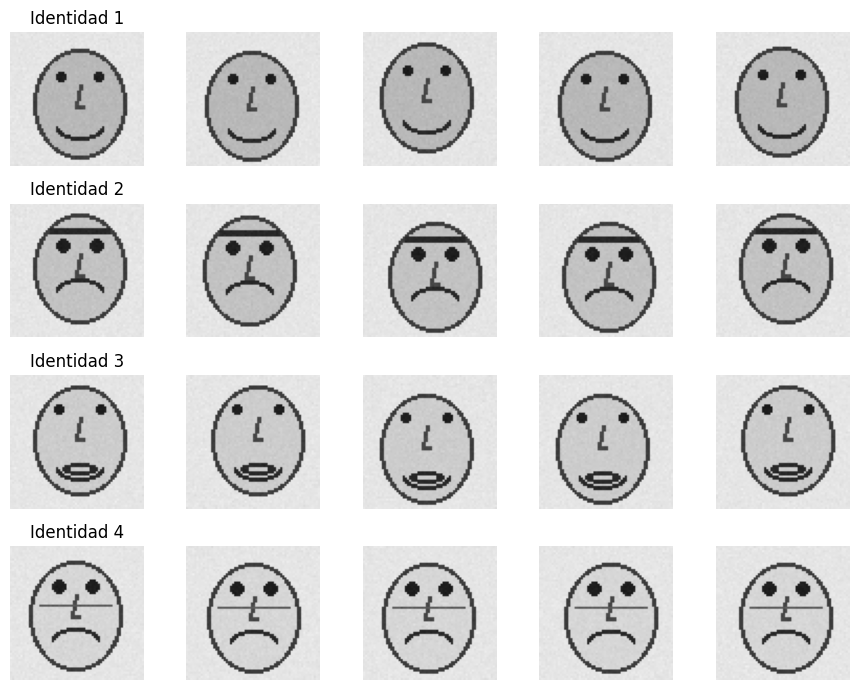

In [5]:
fig, axes = plt.subplots(N_ID, 5, figsize=(9, 7))
for identity in range(N_ID):
    indices = np.where(labels == identity)[0][:5]
    for j, idx in enumerate(indices):
        axes[identity, j].imshow(images[idx], cmap='gray', vmin=0, vmax=255)
        axes[identity, j].axis('off')
        if j == 0:
            axes[identity, j].set_title(f'Identidad {identity + 1}')
plt.tight_layout()
plt.show()

## Convertir las imágenes a tensores

In [6]:
X = torch.tensor(images, dtype=torch.float32).unsqueeze(1) / 255.0
y = torch.tensor(labels, dtype=torch.long)

print('X:', X.shape)
print('y:', y.shape)
print('Rango de X:', float(X.min()), float(X.max()))

X: torch.Size([48, 1, 64, 64])
y: torch.Size([48])
Rango de X: 0.0784313753247261 0.9450980424880981


## Crear el conjunto de tripletas

In [7]:
class TripletFaces(Dataset):
    def __init__(self, X, y, triplets_per_epoch=400):
        self.X = X
        self.y = y
        self.n = triplets_per_epoch
        self.by_class = {
            int(c): torch.where(y == c)[0].tolist()
            for c in torch.unique(y)
        }
        self.classes = list(self.by_class)
        if len(self.classes) < 2:
            raise ValueError('Se necesitan al menos dos identidades.')
        if any(len(indices) < 2 for indices in self.by_class.values()):
            raise ValueError('Cada identidad necesita al menos dos imágenes.')

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        anchor_class = random.choice(self.classes)
        other_classes = [c for c in self.classes if c != anchor_class]
        negative_class = random.choice(other_classes)

        anchor_idx, positive_idx = random.sample(self.by_class[anchor_class], 2)
        negative_idx = random.choice(self.by_class[negative_class])

        return (
            self.X[anchor_idx],
            self.X[positive_idx],
            self.X[negative_idx],
            anchor_class,
            negative_class
        )

##Ver una tripleta

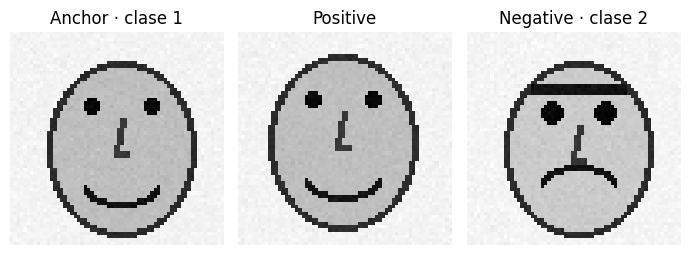

In [8]:
triplets = TripletFaces(X, y, triplets_per_epoch=400)
a, p, n, anchor_class, negative_class = triplets[0]

fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for img, title, ax in [
    (a, f'Anchor · clase {anchor_class + 1}', axes[0]),
    (p, 'Positive', axes[1]),
    (n, f'Negative · clase {negative_class + 1}', axes[2])
]:
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Construir la red que genera embeddings

In [9]:
class Encoder(nn.Module):
    def __init__(self, emb_dim=64):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.fc = nn.Linear(32 * 4 * 4, emb_dim)

    def forward(self, x):
        z = self.features(x)
        z = z.flatten(1)
        z = self.fc(z)
        return F.normalize(z, p=2, dim=1)

## Probar la salida de la red

In [10]:
model = Encoder(emb_dim=64).to(DEVICE)
print(model)

with torch.no_grad():
    example_embedding = model(X[:2].to(DEVICE))
print('Forma del embedding:', example_embedding.shape)

Encoder(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (fc): Linear(in_features=512, out_features=64, bias=True)
)
Forma del embedding: torch.Size([2, 64])


## Preparar el entrenamiento

In [11]:
loader = DataLoader(triplets, batch_size=32, shuffle=True)
criterion = nn.TripletMarginLoss(margin=0.8, p=2)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print('Tripletas por época:', len(triplets))
print('Margen:', 0.8)

Tripletas por época: 400
Margen: 0.8


##Entrenar la red

In [12]:
losses = []
EPOCHS = 18

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    total_items = 0

    for anchor, positive, negative, _, _ in loader:
        anchor = anchor.to(DEVICE)
        positive = positive.to(DEVICE)
        negative = negative.to(DEVICE)

        z_anchor = model(anchor)
        z_positive = model(positive)
        z_negative = model(negative)

        loss = criterion(z_anchor, z_positive, z_negative)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * anchor.size(0)
        total_items += anchor.size(0)

    mean_loss = total_loss / total_items
    losses.append(mean_loss)
    print(f'Época {epoch + 1:02d}/{EPOCHS} · Triplet Loss: {mean_loss:.4f}')

Época 01/18 · Triplet Loss: 0.3981
Época 02/18 · Triplet Loss: 0.0266
Época 03/18 · Triplet Loss: 0.0024
Época 04/18 · Triplet Loss: 0.0001
Época 05/18 · Triplet Loss: 0.0000
Época 06/18 · Triplet Loss: 0.0000
Época 07/18 · Triplet Loss: 0.0000
Época 08/18 · Triplet Loss: 0.0000
Época 09/18 · Triplet Loss: 0.0000
Época 10/18 · Triplet Loss: 0.0003
Época 11/18 · Triplet Loss: 0.0002
Época 12/18 · Triplet Loss: 0.0000
Época 13/18 · Triplet Loss: 0.0000
Época 14/18 · Triplet Loss: 0.0000
Época 15/18 · Triplet Loss: 0.0000
Época 16/18 · Triplet Loss: 0.0000
Época 17/18 · Triplet Loss: 0.0000
Época 18/18 · Triplet Loss: 0.0000


## Graficar la pérdida

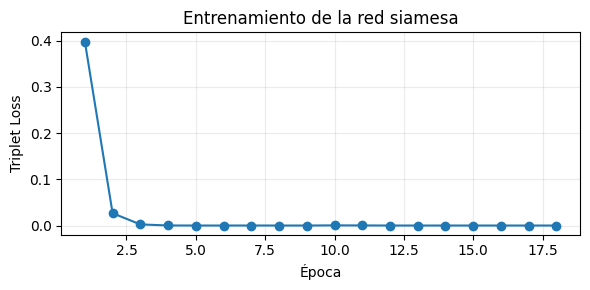

In [13]:
plt.figure(figsize=(6, 3))
plt.plot(range(1, len(losses) + 1), losses, marker='o')
plt.xlabel('Época')
plt.ylabel('Triplet Loss')
plt.title('Entrenamiento de la red siamesa')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Obtener los embeddings

In [14]:
model.eval()
with torch.no_grad():
    Z = model(X.to(DEVICE)).cpu()
print('Forma de los embeddings:', Z.shape)

Forma de los embeddings: torch.Size([48, 64])


## Comparar distancias

Distancia positiva media: 0.1312
Distancia negativa media: 1.5421


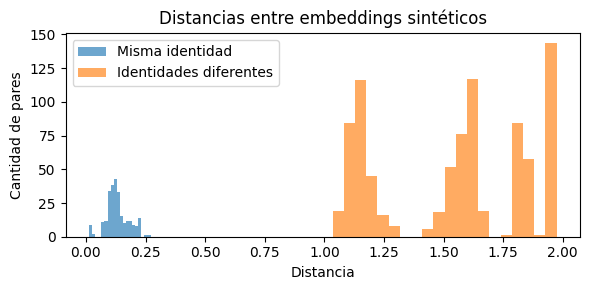

In [15]:
def calculate_pair_distances(embeddings, class_labels):
    positive_distances = []
    negative_distances = []
    rows = []

    for i, j in itertools.combinations(range(len(class_labels)), 2):
        distance = torch.dist(embeddings[i], embeddings[j]).item()
        same = int(class_labels[i] == class_labels[j])
        if same:
            positive_distances.append(distance)
            relation = 'misma_identidad'
        else:
            negative_distances.append(distance)
            relation = 'identidades_diferentes'
        rows.append({
            'relacion': relation,
            'distancia': distance
        })
    return positive_distances, negative_distances, rows

pos, neg, synthetic_pair_rows = calculate_pair_distances(Z, labels)
mean_pos = float(np.mean(pos))
mean_neg = float(np.mean(neg))
print('Distancia positiva media:', round(mean_pos, 4))
print('Distancia negativa media:', round(mean_neg, 4))

plt.figure(figsize=(6, 3))
plt.hist(pos, bins=20, alpha=0.65, label='Misma identidad')
plt.hist(neg, bins=20, alpha=0.65, label='Identidades diferentes')
plt.xlabel('Distancia')
plt.ylabel('Cantidad de pares')
plt.title('Distancias entre embeddings sintéticos')
plt.legend()
plt.tight_layout()
plt.show()

Probar One-shot

In [16]:
reference_indices = {
    c: int(np.where(labels == c)[0][0])
    for c in range(N_ID)
}
query_indices = [i for i in range(len(X)) if i not in reference_indices.values()]

correct_one = 0
one_predictions = []
for i in query_indices:
    distances = {
        c: torch.dist(Z[i], Z[idx]).item()
        for c, idx in reference_indices.items()
    }
    prediction = min(distances, key=distances.get)
    is_correct = prediction == int(labels[i])
    correct_one += int(is_correct)
    one_predictions.append({
        'identidad_real': int(labels[i]) + 1,
        'identidad_predicha': int(prediction) + 1,
        'correcto': bool(is_correct)
    })

accuracy_one = correct_one / len(query_indices)
print(f'One-shot: {accuracy_one:.4f} ({correct_one}/{len(query_indices)})')

One-shot: 1.0000 (44/44)


## Probar Few-shot con tres referencias

In [17]:
reference_ids_3 = {
    c: np.where(labels == c)[0][:3]
    for c in range(N_ID)
}
prototypes_3 = {}
for c, indices in reference_ids_3.items():
    prototype = Z[indices].mean(0, keepdim=True)
    prototypes_3[c] = F.normalize(prototype, p=2, dim=1).squeeze(0)

few_query_indices = [
    i for i in range(len(X))
    if all(i not in ids for ids in reference_ids_3.values())
]
correct_few = 0
few_predictions = []
for i in few_query_indices:
    distances = {
        c: torch.dist(Z[i], prototype).item()
        for c, prototype in prototypes_3.items()
    }
    prediction = min(distances, key=distances.get)
    is_correct = prediction == int(labels[i])
    correct_few += int(is_correct)
    few_predictions.append({
        'identidad_real': int(labels[i]) + 1,
        'identidad_predicha': int(prediction) + 1,
        'correcto': bool(is_correct)
    })

accuracy_few = correct_few / len(few_query_indices)
print(f'Few-shot (3 referencias): {accuracy_few:.4f} ({correct_few}/{len(few_query_indices)})')

Few-shot (3 referencias): 1.0000 (36/36)


Definir el umbral y verificar dos pares

In [18]:
threshold = (mean_pos + mean_neg) / 2
print('Umbral pedagógico:', round(threshold, 4))

def verify_pair(embeddings, i, j, limit):
    distance = torch.dist(embeddings[i], embeddings[j]).item()
    result = 'MISMA IDENTIDAD' if distance < limit else 'IDENTIDADES DIFERENTES'
    return distance, result

same_indices = np.where(labels == 0)[0][:2]
different_indices = (int(np.where(labels == 0)[0][0]),
                     int(np.where(labels == 1)[0][0]))

synthetic_checks_rows = []
for pair_name, pair in [('Par de la misma identidad', tuple(same_indices)),
                        ('Par de identidades diferentes', different_indices)]:
    distance, result = verify_pair(Z, pair[0], pair[1], threshold)
    print(pair_name, '| distancia:', round(distance, 4), '| resultado:', result)
    synthetic_checks_rows.append({
        'par': pair_name,
        'distancia': distance,
        'umbral': threshold,
        'resultado': result
    })

Umbral pedagógico: 0.8367
Par de la misma identidad | distancia: 0.207 | resultado: MISMA IDENTIDAD
Par de identidades diferentes | distancia: 1.2789 | resultado: IDENTIDADES DIFERENTES


In [19]:
from google.colab import files

uploaded = files.upload()
zip_files = [name for name in uploaded if name.lower().endswith('.zip')]
if not zip_files:
    raise ValueError('Carga un archivo ZIP con las carpetas de rostros.')

photo_zip = zip_files[0]
extract_base = Path('/content/carga_rostros')
if extract_base.exists():
    shutil.rmtree(extract_base)
extract_base.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(photo_zip, 'r') as zf:
    for member in zf.infolist():
        destination = (extract_base / member.filename).resolve()
        if extract_base.resolve() not in destination.parents and destination != extract_base.resolve():
            raise ValueError('El ZIP contiene una ruta no permitida.')
    zf.extractall(extract_base)

root_photos = extract_base / 'rostros' if (extract_base / 'rostros').is_dir() else extract_base
person_folders = sorted([p for p in root_photos.iterdir() if p.is_dir()])
print('Carpeta de imágenes:', root_photos)
print('Personas encontradas:', len(person_folders))
if len(person_folders) < 2:
    raise ValueError('Se necesitan al menos dos carpetas, una por persona.')

Saving rostros.zip to rostros.zip
Carpeta de imágenes: /content/carga_rostros
Personas encontradas: 5


Cargar, revisar y procesar las fotografías

Total de fotografías: 25
Persona 1: 5 fotografías
Persona 2: 5 fotografías
Persona 3: 5 fotografías
Persona 4: 5 fotografías
Persona 5: 5 fotografías


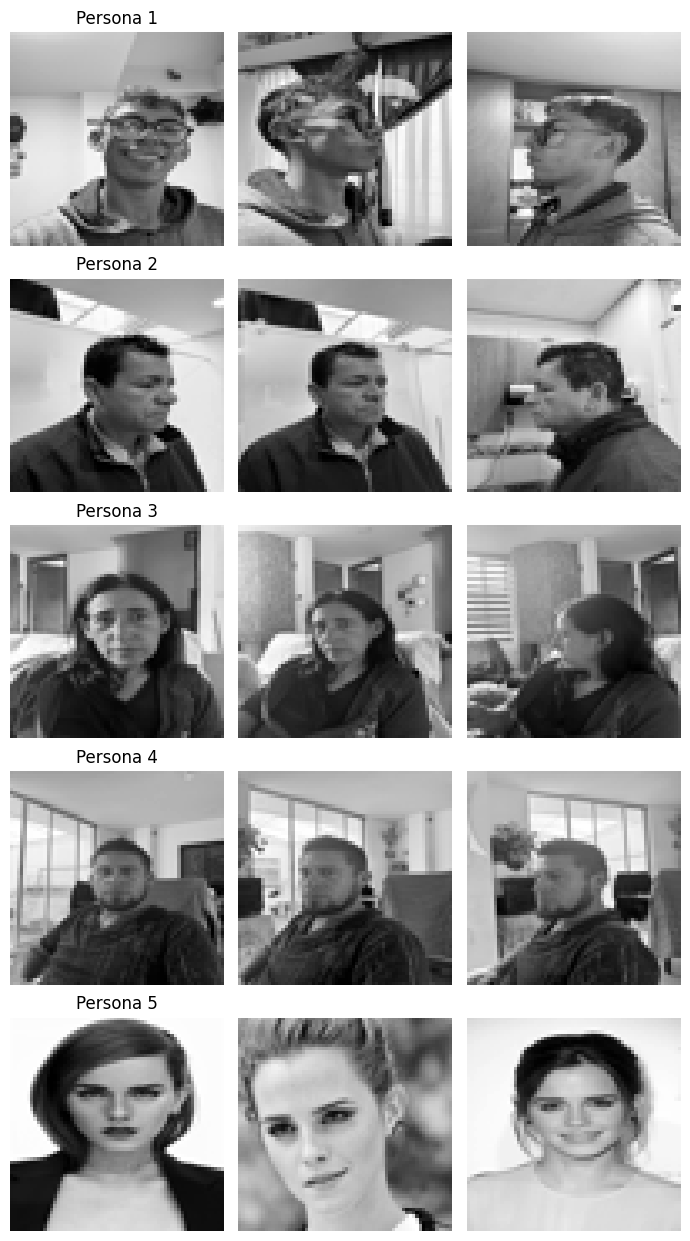

In [20]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp'}
photo_arrays = []
photo_labels = []
photo_counts = {}
photo_file_order = []

for label, folder in enumerate(person_folders):
    files_in_folder = sorted([
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])
    photo_counts[label] = len(files_in_folder)
    if len(files_in_folder) < 3:
        raise ValueError(f'{folder.name}: se requieren al menos tres fotos.')

    for image_path in files_in_folder:
        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert('L').resize((64, 64))
            photo_arrays.append(np.array(image, dtype=np.uint8))
        photo_labels.append(label)
        photo_file_order.append(image_path.name)

photo_arrays = np.stack(photo_arrays)
photo_labels = np.array(photo_labels)

print('Total de fotografías:', len(photo_arrays))
for label, count in photo_counts.items():
    print(f'Persona {label + 1}: {count} fotografías')

fig, axes = plt.subplots(len(person_folders), 3, figsize=(7, 2.5 * len(person_folders)))
axes = np.array(axes).reshape(len(person_folders), 3)
for label in range(len(person_folders)):
    indices = np.where(photo_labels == label)[0][:3]
    for j, idx in enumerate(indices):
        axes[label, j].imshow(photo_arrays[idx], cmap='gray')
        axes[label, j].axis('off')
        if j == 0:
            axes[label, j].set_title(f'Persona {label + 1}')
plt.tight_layout()
plt.show()

### Entrenar con las fotografías y comparar

Para esta segunda prueba se entrena otro encoder con las tres primeras fotos de cada persona. Las fotos adicionales no participan en ese entrenamiento y se utilizan como consultas

In [21]:
photo_train_indices = []
photo_query_indices = []
for label in range(len(person_folders)):
    indices = np.where(photo_labels == label)[0].tolist()
    photo_train_indices.extend(indices[:3])
    photo_query_indices.extend(indices[3:])

photo_X_train = torch.tensor(
    photo_arrays[photo_train_indices], dtype=torch.float32
).unsqueeze(1) / 255.0
photo_y_train = torch.tensor(photo_labels[photo_train_indices], dtype=torch.long)
photo_X_query = torch.tensor(
    photo_arrays[photo_query_indices], dtype=torch.float32
).unsqueeze(1) / 255.0 if photo_query_indices else None
photo_y_query = photo_labels[photo_query_indices] if photo_query_indices else np.array([])

photo_triplets = TripletFaces(photo_X_train, photo_y_train, triplets_per_epoch=240)
photo_loader = DataLoader(photo_triplets, batch_size=16, shuffle=True)
photo_model = Encoder(emb_dim=64).to(DEVICE)
photo_optimizer = torch.optim.Adam(photo_model.parameters(), lr=1e-3)
photo_criterion = nn.TripletMarginLoss(margin=0.8, p=2)
photo_losses = []

for epoch in range(18):
    photo_model.train()
    total_loss = 0.0
    total_items = 0
    for anchor, positive, negative, _, _ in photo_loader:
        anchor = anchor.to(DEVICE)
        positive = positive.to(DEVICE)
        negative = negative.to(DEVICE)
        z_anchor = photo_model(anchor)
        z_positive = photo_model(positive)
        z_negative = photo_model(negative)
        loss = photo_criterion(z_anchor, z_positive, z_negative)
        photo_optimizer.zero_grad()
        loss.backward()
        photo_optimizer.step()
        total_loss += loss.item() * anchor.size(0)
        total_items += anchor.size(0)
    photo_losses.append(total_loss / total_items)

photo_model.eval()
with torch.no_grad():
    photo_Z_train = photo_model(photo_X_train.to(DEVICE)).cpu()
    photo_Z_query = (photo_model(photo_X_query.to(DEVICE)).cpu()
                     if photo_X_query is not None else None)

print('Entrenamiento con fotos terminado.')
print('Última Triplet Loss:', round(photo_losses[-1], 4))

Entrenamiento con fotos terminado.
Última Triplet Loss: 0.0


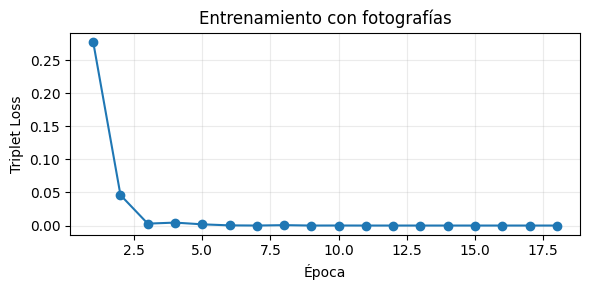

Distancia positiva media: 0.209
Distancia negativa media: 1.5273
Umbral pedagógico: 0.8682


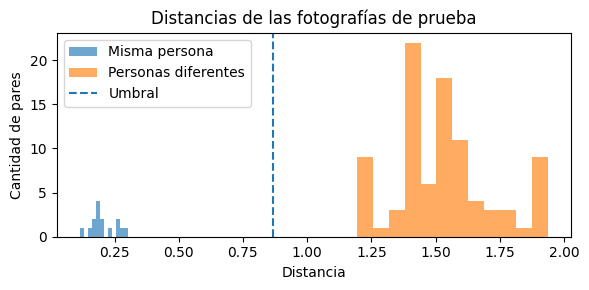

In [22]:
plt.figure(figsize=(6, 3))
plt.plot(range(1, len(photo_losses) + 1), photo_losses, marker='o')
plt.xlabel('Época')
plt.ylabel('Triplet Loss')
plt.title('Entrenamiento con fotografías')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

photo_pos, photo_neg, photo_pair_rows = calculate_pair_distances(
    photo_Z_train, photo_y_train.numpy()
)
photo_mean_pos = float(np.mean(photo_pos))
photo_mean_neg = float(np.mean(photo_neg))
photo_threshold = (photo_mean_pos + photo_mean_neg) / 2
print('Distancia positiva media:', round(photo_mean_pos, 4))
print('Distancia negativa media:', round(photo_mean_neg, 4))
print('Umbral pedagógico:', round(photo_threshold, 4))

plt.figure(figsize=(6, 3))
plt.hist(photo_pos, bins=12, alpha=0.65, label='Misma persona')
plt.hist(photo_neg, bins=12, alpha=0.65, label='Personas diferentes')
plt.axvline(photo_threshold, linestyle='--', label='Umbral')
plt.xlabel('Distancia')
plt.ylabel('Cantidad de pares')
plt.title('Distancias de las fotografías de prueba')
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
photo_same = np.where(photo_y_train.numpy() == 0)[0][:2]
photo_different = (
    int(np.where(photo_y_train.numpy() == 0)[0][0]),
    int(np.where(photo_y_train.numpy() == 1)[0][0])
)

photo_checks_rows = []
for name, pair in [
    ('Misma persona', tuple(photo_same)),
    ('Personas diferentes', photo_different)
]:
    distance, result = verify_pair(photo_Z_train, pair[0], pair[1], photo_threshold)
    print(name, '| distancia:', round(distance, 4), '| resultado:', result)
    photo_checks_rows.append({
        'par': name,
        'distancia': distance,
        'umbral': photo_threshold,
        'resultado': result
    })

Misma persona | distancia: 0.1629 | resultado: MISMA IDENTIDAD
Personas diferentes | distancia: 1.4026 | resultado: IDENTIDADES DIFERENTES


In [24]:
photo_one_accuracy = None
photo_few_accuracy = None
photo_one_predictions = []
photo_few_predictions = []

if all(photo_counts[label] >= 4 for label in range(len(person_folders))):
    # Una referencia por persona.
    one_refs = {}
    three_refs = {}
    start = 0
    for label in range(len(person_folders)):
        one_refs[label] = photo_Z_train[start]
        three_refs[label] = F.normalize(
            photo_Z_train[start:start + 3].mean(0, keepdim=True), p=2, dim=1
        ).squeeze(0)
        start += 3

    one_correct = 0
    few_correct = 0
    for idx, true_label in enumerate(photo_y_query.tolist()):
        one_distances = {c: torch.dist(photo_Z_query[idx], ref).item()
                         for c, ref in one_refs.items()}
        few_distances = {c: torch.dist(photo_Z_query[idx], ref).item()
                         for c, ref in three_refs.items()}
        one_pred = min(one_distances, key=one_distances.get)
        few_pred = min(few_distances, key=few_distances.get)
        one_ok = one_pred == true_label
        few_ok = few_pred == true_label
        one_correct += int(one_ok)
        few_correct += int(few_ok)
        photo_one_predictions.append({
            'identidad_real': f'persona_{true_label + 1:02d}',
            'identidad_predicha': f'persona_{one_pred + 1:02d}',
            'correcto': bool(one_ok)
        })
        photo_few_predictions.append({
            'identidad_real': f'persona_{true_label + 1:02d}',
            'identidad_predicha': f'persona_{few_pred + 1:02d}',
            'correcto': bool(few_ok)
        })

    photo_one_accuracy = one_correct / len(photo_y_query)
    photo_few_accuracy = few_correct / len(photo_y_query)
    print(f'One-shot con fotos: {photo_one_accuracy:.4f} ({one_correct}/{len(photo_y_query)})')
    print(f'Few-shot con fotos: {photo_few_accuracy:.4f} ({few_correct}/{len(photo_y_query)})')
else:
    print('No hay fotos de consulta independientes.')
    print('Se necesitan al menos cuatro fotos por persona para medir One-shot y Few-shot sin reutilizar las referencias.')
    print('La prueba con fotos queda como demostración de embeddings y distancias.')

One-shot con fotos: 0.7000 (7/10)
Few-shot con fotos: 0.7000 (7/10)
